In [1]:
import matplotlib.pyplot as plt
import numpy as np

In [2]:
d = 0.2032
rho = 1.2
n = 8000/60
e = 1e-6
rpm = n*60

In [3]:
def thrust_rpm(rpm):
    CT = 2e-15 * (rpm) ** 3 - 4e-11 * (rpm) ** 2 + 3e-7 * (rpm) + 0.1013
    n = rpm/60
    thrust = CT * rho * (n ** 2) *  d ** 4
    return thrust

In [4]:
def torque_rpm(RPM):
    return 4e-14 * RPM ** 3 + 8e-12 * RPM ** 2 + 3e-6 * RPM

In [5]:
torque_plot = []
thrust_plot = []
for i in range(0,16000,100):
    torque_plot.append(torque_rpm(i))
    thrust_plot.append(thrust_rpm(i))

len(torque_plot)
# len(list(range(0,16000,100)))

160

In [6]:
torque_plot = np.array(torque_plot)
thrust_plot = np.array(thrust_plot)

Text(0.5, 1.0, 'thrust')

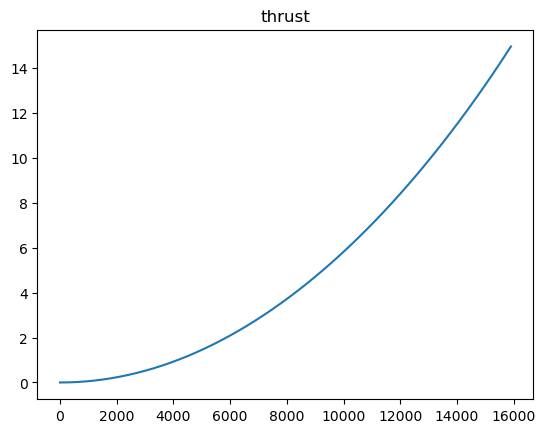

In [7]:
plt.figure()
plt.plot(list(range(0,16000,100)), thrust_plot)
plt.title('thrust')

Text(0.5, 1.0, 'torque')

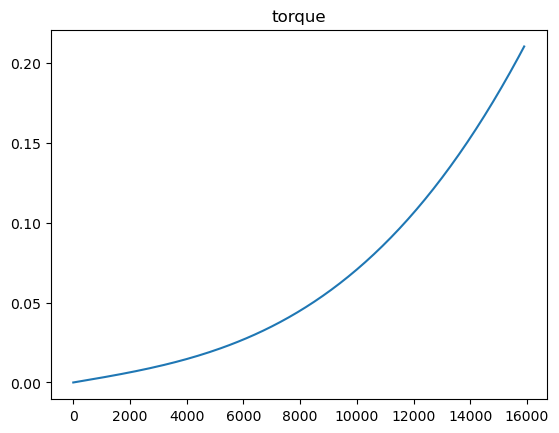

In [8]:
plt.figure()
plt.plot(list(range(0,16000,100)), torque_plot)
plt.title('torque')

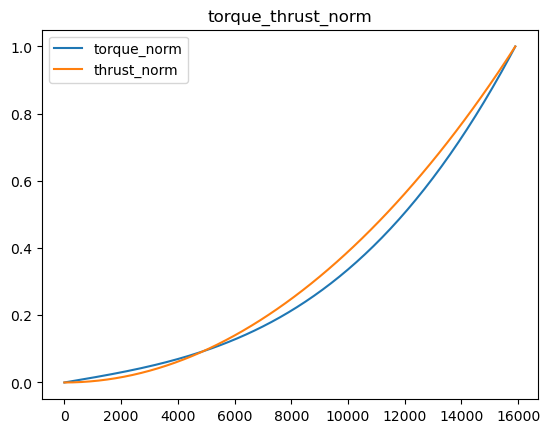

In [9]:
plt.figure()
torque_plot_norm = torque_plot / max(torque_plot)
thrust_plot_norm = thrust_plot / max(thrust_plot)
plt.title('torque_thrust_norm')
plt.plot(list(range(0,16000,100)), torque_plot_norm, label='torque_norm')
plt.plot(list(range(0,16000,100)), thrust_plot_norm, label='thrust_norm')
plt.legend();

In [10]:
kq_plot = []
perturb_plot = []
rpm = 0
for i in range(10,160,1):
    e = 100 * (i+1)
    kq = (torque_rpm(rpm + e) - torque_rpm(rpm-e))/(thrust_rpm(rpm + e) - thrust_rpm(rpm - e))
    kq_plot.append(kq)
    perturb_plot.append(rpm + e)


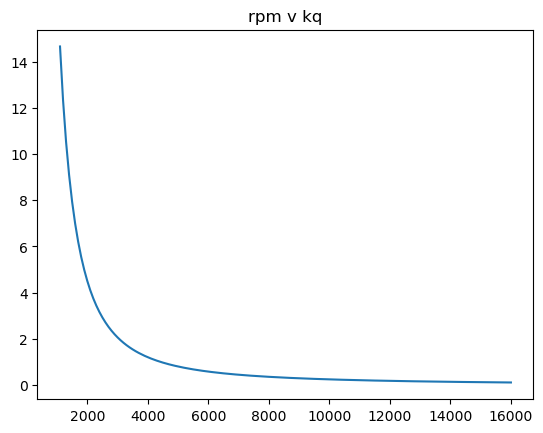

In [11]:

plt.plot(perturb_plot, kq_plot)
plt.title('rpm v kq');

In [12]:
def numerical_derivative(func, rpm, epsilon=1.0):
    return (
        func(rpm + epsilon) - func(rpm - epsilon)
    ) / (2 * epsilon)

In [13]:
rpm = np.linspace(100, 16000, 1000)
dQ_dRPM = numerical_derivative(torque_rpm, rpm)
dT_dRPM = numerical_derivative(thrust_rpm, rpm)

kQ = dQ_dRPM / dT_dRPM

Text(0.5, 1.0, 'dQ/dRPM')

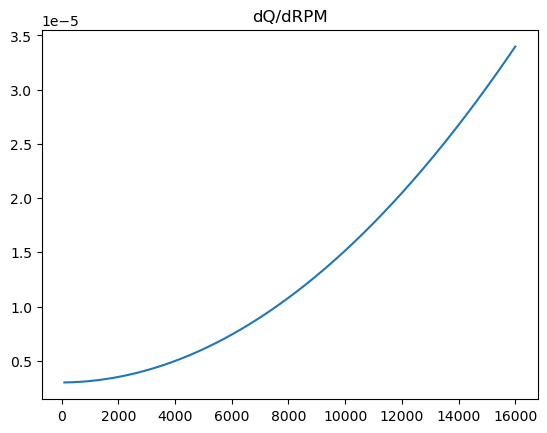

In [14]:
plt.figure()
plt.plot(rpm, dQ_dRPM)
plt.title('dQ/dRPM')

Text(0.5, 1.0, 'dQ/dRPM')

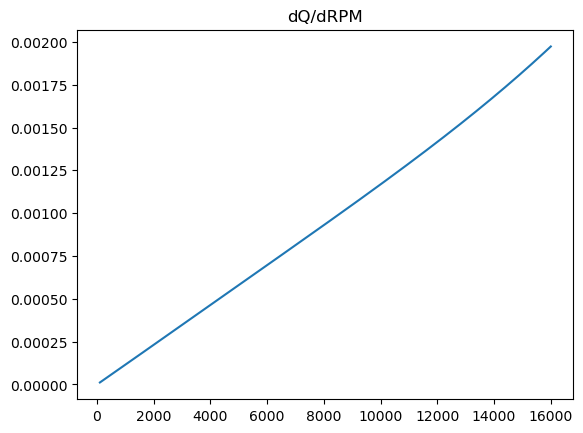

In [15]:
plt.figure()
plt.plot(rpm, dT_dRPM)
plt.title('dQ/dRPM')

Text(0.5, 1.0, 'kQ')

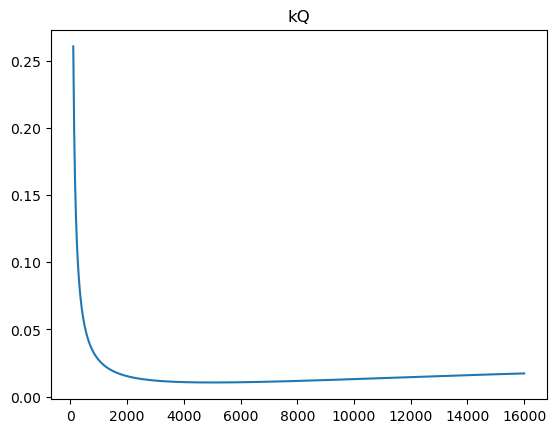

In [16]:
plt.figure()
plt.plot(rpm, kQ)
plt.title('kQ')